In [1]:
#0. 모듈 사용
import tensorflow as tf

In [2]:
#1. 데이터셋 불러오기
dataset_path="Dataset/korean_food_photos"

#1.1)훈련용 데이터셋 - 전체 이미지 중 80%  [하위폴더 구조로 분류명이 있을때]
train_dataset= tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset='training', #현재 만드는 데이터셋이 [훈련용]임을 지정
    seed=42,
    image_size=(224,224),  # 전이학습에 사용할 기본모델 efficientNet 이 224x224로 훈련했기에.
    batch_size= 32
)

Found 920 files belonging to 21 classes.
Using 736 files for training.


In [3]:
#1.2)테스트용 데이터셋 - 전체 이미지 중 20%  [하위폴더 구조로 분류명이 있을때]
test_dataset= tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset='validation', #현재 만드는 데이터셋이 [검증용]임을 지정
    seed=42,
    image_size=(224,224),  # 전이학습에 사용할 기본모델 efficientNet 이 224x224로 훈련했기에.
    batch_size= 32
)

Found 920 files belonging to 21 classes.
Using 184 files for validation.


In [4]:
#2. 이미지들의 분류명(클래스명) 얻어오기
class_names= train_dataset.class_names
print(class_names)

['bibimbap', 'bob', 'bossam', 'bulgogi', 'daegaejjim', 'dakbokkeumtang', 'doenjang_chigae', 'galbijjim', 'galchijorim', 'ganjang_gejang', 'gimbob', 'jeyuk_bokkeum', 'jjajangmyeon', 'kimchi', 'nangmyeon', 'ojingeo_bokkeum', 'pajeon', 'samgupsal', 'samgyetang', 'soondae', 'soondubu_jjigae']


In [ ]:
#3. 성능 최적화를 위해 prefetch 설정 [다음에 학습할 데이터를 미리 메모리에 로딩해놓기]
AUTOTUNE= tf.data.AUTOTUNE

train_ds= train_dataset.prefetch(buffer_size=AUTOTUNE)
test_ds= test_dataset.prefetch(buffer_size=AUTOTUNE)

In [6]:
#4. 전이학습에 필요한 사전학습모델 준비하기
base_model= tf.keras.applications.EfficientNetV2B0(
    input_shape=(224,224,3), #가로,세로,채널
    include_top= False,  #모델의 마지막 분류층을 포함할지 여부, True로 하면 1000개 분류모델이 됨
    weights='imagenet'   # 사전 학습된 가중치(weight)을 지정 (ImageNet 1400만장으로 훈련한 값)
)
#이 사전학습 모델을 새로이 훈련하면 안되기에..
base_model.trainable = False 

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
#5. 나만의 한국음식이미지분류 모델 만들기 - 전이학습
model= tf.keras.Sequential([
    tf.keras.layers.InputLayer(shape=(224,224,3)), #입력층
    tf.keras.layers.Lambda( tf.keras.applications.efficientnet_v2.preprocess_input ),  #전처리
    base_model,
    #나만의 특성추출기 추가
    tf.keras.layers.Conv2D(128, kernel_size=1, activation='relu', use_bias=False), #128개의 새로운 특성 발견.
    #분류의 마지막 출력층 만들기
    tf.keras.layers.Conv2D(len(class_names), kernel_size=1, use_bias=False), #분류개수 21개
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Activation('softmax')
])

In [8]:
#5-1] Sequential API 기반 코드를 Keras Functinal API 구조로 변환(권장)

inputs= tf.keras.layers.Input(shape=(224,224,3)) #입력층

x= tf.keras.layers.Lambda( tf.keras.applications.efficientnet_v2.preprocess_input )(inputs) #전처리(정규화)
x= base_model(x)
x= tf.keras.layers.Conv2D(128, kernel_size=1, activation='relu', use_bias=False)(x)
x= tf.keras.layers.Conv2D(len(class_names), kernel_size=1, use_bias=False)(x)
x= tf.keras.layers.GlobalAveragePooling2D()(x)

outputs= tf.keras.layers.Activation('softmax')(x)

#위 함수 체인 구조로 모델을 생성
model= tf.keras.Model(inputs=inputs, outputs=outputs )


In [9]:
#6. 모델 학습을 위한 구성요소 [손실함수,최적화]
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [10]:
#7. 만들어진 모델의 신경망 구조를 간략하게 살펴보기
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │       163,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 21)       │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 21)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 21)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,085,840 (23.22 MB)

 Trainable params: 166,528 (650.50 KB)

 Non-trainable params: 5,919,312 (22.58 MB)

In [12]:
#8. 모델 학습
history= model.fit(
    train_ds,
    validation_data=test_ds,
    batch_size=32, 
    epochs=10
)

Epoch 1/10


c:\Users\YOLO\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


23/23 ━━━━━━━━━━━━━━━━━━━━ 8s 356ms/step - accuracy: 0.5761 - loss: 1.9289 - val_accuracy: 0.4565 - val_loss: 2.0987
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 8s 341ms/step - accuracy: 0.5938 - loss: 1.8149 - val_accuracy: 0.4837 - val_loss: 2.0032
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 8s 350ms/step - accuracy: 0.6291 - loss: 1.7104 - val_accuracy: 0.5109 - val_loss: 1.9182
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 8s 338ms/step - accuracy: 0.6495 - loss: 1.6061 - val_accuracy: 0.5163 - val_loss: 1.8431
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 8s 334ms/step - accuracy: 0.6902 - loss: 1.5167 - val_accuracy: 0.5598 - val_loss: 1.7715
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 8s 334ms/step - accuracy: 0.6943 - loss: 1.4434 - val_accuracy: 0.5489 - val_loss: 1.7065
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 8s 341ms/step - accuracy: 0.7079 - loss: 1.3737 - val_accuracy: 0.5652 - val_loss: 1.6525
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 8s 340ms/step - accuracy: 0.7418 - loss: 1.2936 - val_accuracy: 0.5924 - val_

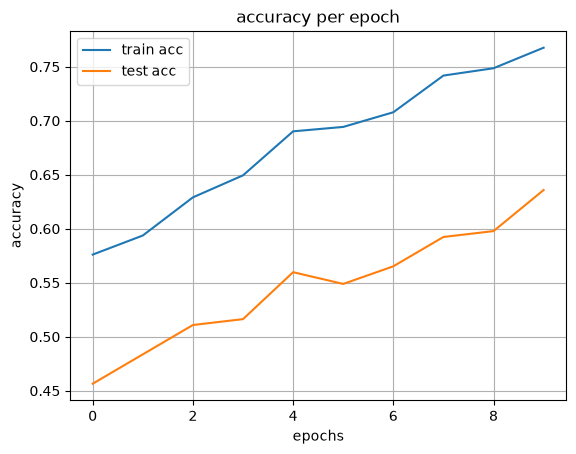

In [14]:
#9. 학습 결과 시각화
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='test acc')
plt.title('accuracy per epoch')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.grid(True)
plt.legend()
plt.show()

In [15]:
# 새로운 이미지의 경로를 주면 분류해주는 기능 함수 만들어놓기
#from tf.keras.preprocessing import image
from keras.preprocessing import image
import numpy as np
def predict_image(img_path):
    #이미지 경로를 통해 Tensorflow에서 인식하는 Image객체를 생성
    img = image.load_img(img_path, target_size=(224,224))
    #이미지 객체를 배열로 변환
    img_array= image.img_to_array(img)
    #3차원 텐서데이터 --> 4차원텐서 (배치사이즈추가) [배치크기,높이,너비,채널]
    img_array= tf.expand_dims(img_array, 0) #0차원 위치에 배치크기 추가

    #이미지텐서 데이터를 모델에게 주고 예측을 요청
    predictions= model.predict(img_array)
    predicted_food_name= class_names[ np.argmax(predictions) ] #분류명
    confidence= np.max(predictions) #신뢰점수-확률값

    print(f"예측: {predicted_food_name} ({confidence:.2f})")


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
예측: bibimbap (0.40)


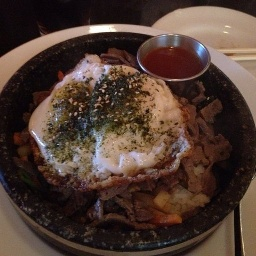

In [17]:
#위 함수를 이용하여 새로운 음식이미지에 대한 분류 요청
predict_image(img_path="Test Images/image01.jpg")

#이미지를 표시하기
from PIL import Image
from IPython.display import display

img= Image.open("Test Images/image01.jpg")
display(img)

In [18]:
predict_image(img_path="Test Images/image02.jpg")
predict_image(img_path="Test Images/image03.jpg")
predict_image(img_path="Test Images/image04.jpg")
predict_image(img_path="Test Images/image05.jpg")
predict_image(img_path="Test Images/image06.jpg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
예측: kimchi (0.39)
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
예측: gimbob (0.73)
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
예측: bossam (0.42)
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
예측: kimchi (0.32)
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
예측: samgyetang (0.52)
